In [1]:
from pathlib import Path
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 120)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
PROJECT_DIR = Path.home() / "projects" / "uber-eats-intelligence"

DATA_PATH = PROJECT_DIR / "data" / "raw" / "reviews.csv"

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
REPORTS_DIR = PROJECT_DIR / "reports"

for folder in [PROCESSED_DIR, FIGURES_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Update PROJECT_DIR to match your actual project location."
    )

reviews = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", reviews.shape)
print("Columns:", reviews.columns.tolist())

display(reviews.head())

Dataset loaded successfully.
Dataset shape: (1984, 6)
Columns: ['review_id', 'order_id', 'customer_id', 'rating', 'review_text', 'review_timestamp']


,review_id,order_id,customer_id,rating,review_text,review_timestamp
0,REV00001,O001580,C0026,3,Nothing special,2026-06-09
1,REV00002,O003792,C0296,5,Fast delivery and delicious food,2026-06-30
2,REV00003,O004504,C0108,4,Nice experience,2026-04-12
3,REV00004,O004105,C0018,4,Nice experience,2026-06-28
4,REV00005,O000164,C0365,4,Would order again,2026-09-25


In [3]:
TEXT_COL = "review_text"
RATING_COL = "rating"

required_columns = [TEXT_COL, RATING_COL]

missing_columns = [
    column for column in required_columns
    if column not in reviews.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

print("Missing review texts:", reviews[TEXT_COL].isna().sum())
print("Missing ratings:", reviews[RATING_COL].isna().sum())
print("Duplicate review texts:", reviews[TEXT_COL].duplicated().sum())

# Remove missing or invalid records
reviews = reviews.dropna(
    subset=[TEXT_COL, RATING_COL]
).copy()

reviews[TEXT_COL] = reviews[TEXT_COL].astype(str).str.strip()
reviews[RATING_COL] = pd.to_numeric(
    reviews[RATING_COL], errors="coerce"
)

reviews = reviews.dropna(subset=[RATING_COL])
reviews = reviews[reviews[TEXT_COL] != ""].copy()

# Create rating-derived sentiment labels
reviews["sentiment"] = np.select(
    [
        reviews[RATING_COL].between(1, 2),
        reviews[RATING_COL] == 3,
        reviews[RATING_COL].between(4, 5)
    ],
    [
        "negative",
        "neutral",
        "positive"
    ],
    default="unknown"
)

reviews = reviews[
    reviews["sentiment"] != "unknown"
].copy()

print("Valid rows:", len(reviews))
print("Unique review texts:", reviews[TEXT_COL].nunique())

display(
    reviews["sentiment"]
    .value_counts()
    .rename_axis("sentiment")
    .reset_index(name="count")
)

Missing review texts: 0
Missing ratings: 0
Duplicate review texts: 1969
Valid rows: 1984
Unique review texts: 15


,sentiment,count
0,positive,1436
1,neutral,274
2,negative,274


In [4]:
review_check = (
    reviews.groupby(TEXT_COL, as_index=False)
    .agg(
        occurrences=(TEXT_COL, "size"),
        unique_ratings=(RATING_COL, "nunique"),
        ratings=(RATING_COL, lambda x: sorted(x.unique())),
        sentiments=(
            "sentiment",
            lambda x: sorted(x.unique())
        )
    )
    .sort_values("occurrences", ascending=False)
)

print("Original valid rows:", len(reviews))
print("Unique review texts:", reviews[TEXT_COL].nunique())

display(review_check)

review_check.to_csv(
    PROCESSED_DIR / "review_template_quality_check.csv",
    index=False
)

Original valid rows: 1984
Unique review texts: 15


,review_text,occurrences,unique_ratings,ratings,sentiments
4,Excellent food and service,301,1,[5],[positive]
5,Fast delivery and delicious food,273,1,[5],[positive]
0,Amazing experience,264,1,[5],[positive]
10,Nice experience,216,1,[4],[positive]
14,Would order again,197,1,[4],[positive]
9,Good food and quick delivery,185,1,[4],[positive]
8,Food was okay,97,1,[3],[neutral]
11,Nothing special,90,1,[3],[neutral]
1,Average experience,87,1,[3],[neutral]
3,Delivery was slow,69,1,[2],[negative]


In [5]:
stop_words = set(ENGLISH_STOP_WORDS) - {
    "no", "not", "nor"
}

def clean_text(text):
    text = str(text).lower()

    # Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Keep alphabetic characters and spaces
    text = re.sub(
        r"[^a-z\s]",
        " ",
        text
    )

    # Remove stop words while preserving negation
    tokens = [
        word for word in text.split()
        if word not in stop_words
    ]

    return " ".join(tokens)


reviews["cleaned_text"] = reviews[TEXT_COL].apply(clean_text)

display(
    reviews[
        [TEXT_COL, "cleaned_text", RATING_COL, "sentiment"]
    ].head(10)
)

reviews.to_csv(
    PROCESSED_DIR / "cleaned_reviews.csv",
    index=False
)

,review_text,cleaned_text,rating,sentiment
0,Nothing special,special,3,neutral
1,Fast delivery and delicious food,fast delivery delicious food,5,positive
2,Nice experience,nice experience,4,positive
3,Nice experience,nice experience,4,positive
4,Would order again,order,4,positive
5,Food quality was disappointing,food quality disappointing,2,negative
6,Nice experience,nice experience,4,positive
7,Good food and quick delivery,good food quick delivery,4,positive
8,Would order again,order,4,positive
9,Excellent food and service,excellent food service,5,positive


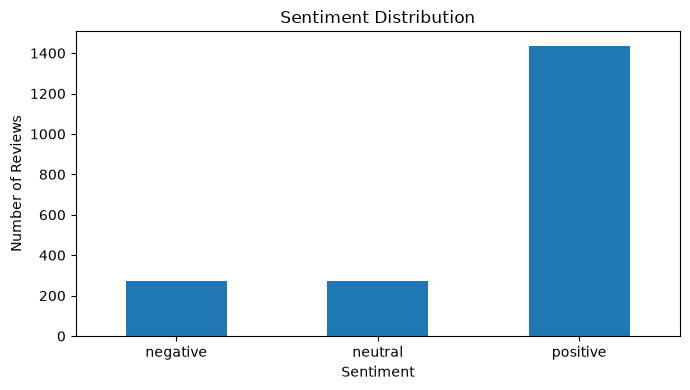

In [6]:
sentiment_counts = (
    reviews["sentiment"]
    .value_counts()
    .reindex(
        ["negative", "neutral", "positive"],
        fill_value=0
    )
)

ax = sentiment_counts.plot(
    kind="bar",
    figsize=(7, 4)
)

ax.set_title("Sentiment Distribution")
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of Reviews")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sentiment_distribution.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [18]:
X = reviews["cleaned_text"].fillna("")
y = reviews["sentiment"].astype(str)

# Every class must have at least two examples
if y.value_counts().min() < 2:
    raise ValueError(
        "Each sentiment class needs at least two examples "
        "for a stratified train/test split."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training rows: 1488
Testing rows: 496

Training sentiment distribution:
sentiment
positive    1077
neutral      206
negative     205
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
positive    359
negative     69
neutral      68
Name: count, dtype: int64


In [19]:
models = {
    "Naive Bayes": Pipeline([
        (
            "tfidf",
            TfidfVectorizer(ngram_range=(1, 2))
        ),
        (
            "model",
            MultinomialNB()
        )
    ]),

    "Linear SVM": Pipeline([
        (
            "tfidf",
            TfidfVectorizer(ngram_range=(1, 2))
        ),
        (
            "model",
            LinearSVC(random_state=RANDOM_STATE)
        )
    ])
}

predictions = {}
evaluation_rows = []

class_order = [
    "negative",
    "neutral",
    "positive"
]

for model_name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    predictions[model_name] = y_pred

    evaluation_rows.append({
        "method": model_name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision_macro": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "recall_macro": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "f1_macro": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        )
    })

    print(f"\n--- {model_name} ---")

    print(
        classification_report(
            y_test,
            y_pred,
            labels=class_order,
            zero_division=0
        )
    )

evaluation_df = pd.DataFrame(evaluation_rows)

display(evaluation_df)

evaluation_df.to_csv(
    PROCESSED_DIR / "model_evaluation.csv",
    index=False
)


--- Naive Bayes ---
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00        69
     neutral       1.00      1.00      1.00        68
    positive       1.00      1.00      1.00       359

    accuracy                           1.00       496
   macro avg       1.00      1.00      1.00       496
weighted avg       1.00      1.00      1.00       496


--- Linear SVM ---
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00        69
     neutral       1.00      1.00      1.00        68
    positive       1.00      1.00      1.00       359

    accuracy                           1.00       496
   macro avg       1.00      1.00      1.00       496
weighted avg       1.00      1.00      1.00       496



,method,accuracy,precision_macro,recall_macro,f1_macro
0,Naive Bayes,1.0,1.0,1.0,1.0
1,Linear SVM,1.0,1.0,1.0,1.0


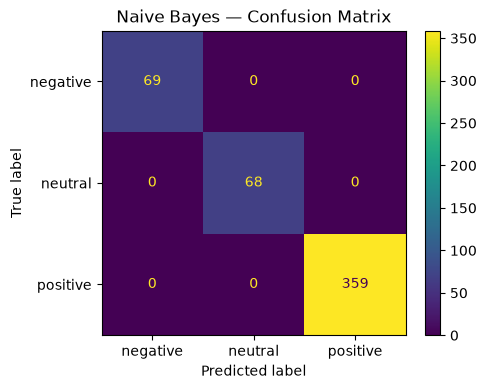

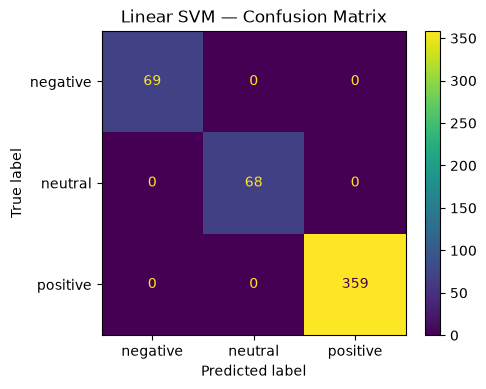

In [20]:
for model_name, y_pred in predictions.items():

    fig, ax = plt.subplots(figsize=(5, 4))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=class_order,
        display_labels=class_order,
        values_format="d",
        ax=ax
    )

    ax.set_title(
        f"{model_name} — Confusion Matrix"
    )

    plt.tight_layout()

    if model_name == "Naive Bayes":
        filename = "naive_bayes_confusion_matrix.png"
    else:
        filename = "linear_svm_confusion_matrix.png"

    plt.savefig(
        FIGURES_DIR / filename,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

In [10]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

def analyze_vader(text):
    compound_score = analyzer.polarity_scores(
        str(text)
    )["compound"]

    if compound_score >= 0.05:
        sentiment = "positive"
    elif compound_score <= -0.05:
        sentiment = "negative"
    else:
        sentiment = "neutral"

    return compound_score, sentiment


# Assign columns directly so rerunning the cell does not
# create duplicate vader_sentiment columns.
vader_results = reviews[TEXT_COL].apply(analyze_vader)

reviews["vader_compound"] = [
    result[0] for result in vader_results
]

reviews["vader_sentiment"] = [
    result[1] for result in vader_results
]

display(
    reviews[
        [
            TEXT_COL,
            RATING_COL,
            "sentiment",
            "vader_compound",
            "vader_sentiment"
        ]
    ].head(10)
)

,review_text,rating,sentiment,vader_compound,vader_sentiment
0,Nothing special,3,neutral,-0.3089,negative
1,Fast delivery and delicious food,5,positive,0.5719,positive
2,Nice experience,4,positive,0.4215,positive
3,Nice experience,4,positive,0.4215,positive
4,Would order again,4,positive,0.0000,neutral
5,Food quality was disappointing,2,negative,-0.4939,negative
6,Nice experience,4,positive,0.4215,positive
7,Good food and quick delivery,4,positive,0.4404,positive
8,Would order again,4,positive,0.0000,neutral
9,Excellent food and service,5,positive,0.5719,positive


,method,accuracy,precision_macro,recall_macro,f1_macro
0,Naive Bayes,1.000000,1.000000,1.000000,1.000000
1,Linear SVM,1.000000,1.000000,1.000000,1.000000
2,VADER,0.737903,0.537504,0.513031,0.519525


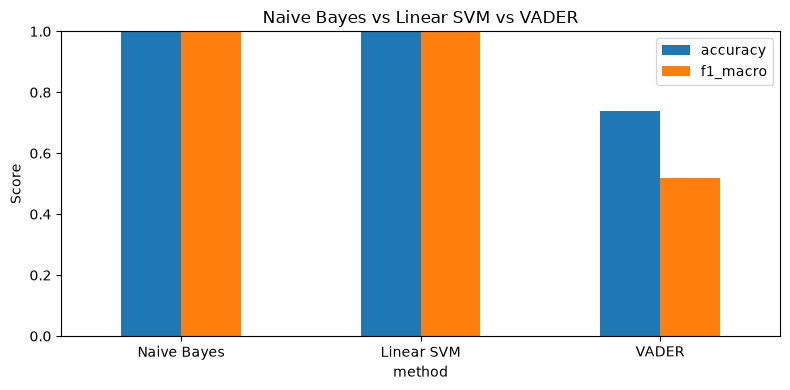

In [11]:
comparison_rows = evaluation_rows.copy()

vader_test = (
    reviews.loc[X_test.index, "vader_sentiment"]
    .astype(str)
)

comparison_rows.append({
    "method": "VADER",
    "accuracy": accuracy_score(y_test, vader_test),
    "precision_macro": precision_score(
        y_test, vader_test,
        average="macro",
        zero_division=0
    ),
    "recall_macro": recall_score(
        y_test, vader_test,
        average="macro",
        zero_division=0
    ),
    "f1_macro": f1_score(
        y_test, vader_test,
        average="macro",
        zero_division=0
    )
})

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df)

comparison_df.to_csv(
    PROCESSED_DIR / "sentiment_method_comparison.csv",
    index=False
)

ax = comparison_df.set_index("method")[
    ["accuracy", "f1_macro"]
].plot(
    kind="bar",
    figsize=(8, 4)
)

ax.set_title("Naive Bayes vs Linear SVM vs VADER")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sentiment_method_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

,term,mean_tfidf
19,experience,0.125587
22,food,0.120120
35,order,0.107527
12,delivery,0.082732
1,amazing experience,0.078779
0,amazing,0.078779
18,excellent food,0.074640
17,excellent,0.074640
27,food service,0.074640
40,service,0.074640


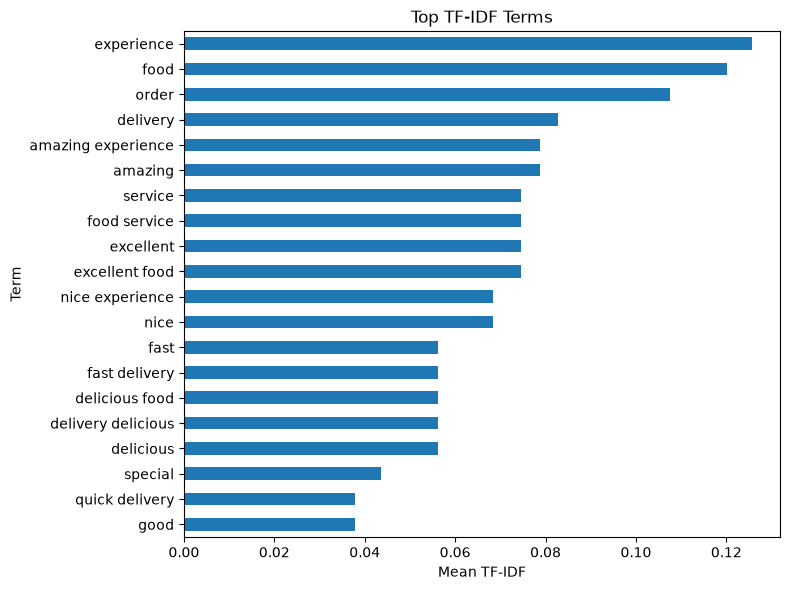

In [12]:
explore_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2)
)

train_matrix = explore_vectorizer.fit_transform(
    X_train
)

terms = explore_vectorizer.get_feature_names_out()

mean_scores = np.asarray(
    train_matrix.mean(axis=0)
).ravel()

top_terms_df = pd.DataFrame({
    "term": terms,
    "mean_tfidf": mean_scores
})

top_terms_df = (
    top_terms_df
    .sort_values("mean_tfidf", ascending=False)
    .head(20)
)

display(top_terms_df)

top_terms_df.to_csv(
    PROCESSED_DIR / "top_tfidf_terms.csv",
    index=False
)

ax = top_terms_df.sort_values(
    "mean_tfidf"
).plot(
    x="term",
    y="mean_tfidf",
    kind="barh",
    legend=False,
    figsize=(8, 6)
)

ax.set_title("Top TF-IDF Terms")
ax.set_xlabel("Mean TF-IDF")
ax.set_ylabel("Term")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "top_tfidf_terms.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Negative review rows: 274


,review_text,rating,cleaned_text
5,Food quality was disappointing,2,food quality disappointing
17,Food quality was disappointing,2,food quality disappointing
18,Food quality was disappointing,2,food quality disappointing
22,Could be much better,2,better
24,Could be much better,2,better
26,Could be much better,2,better
29,Very late delivery and cold food,1,late delivery cold food
32,Very late delivery and cold food,1,late delivery cold food
37,Very late delivery and cold food,1,late delivery cold food
39,Terrible experience,1,terrible experience


,term,count
0,food,103
1,delivery,96
2,slow,69
3,better,66
4,quality,49
5,disappointing,49
6,terrible,36
7,experience,36
8,late,27
9,cold,27


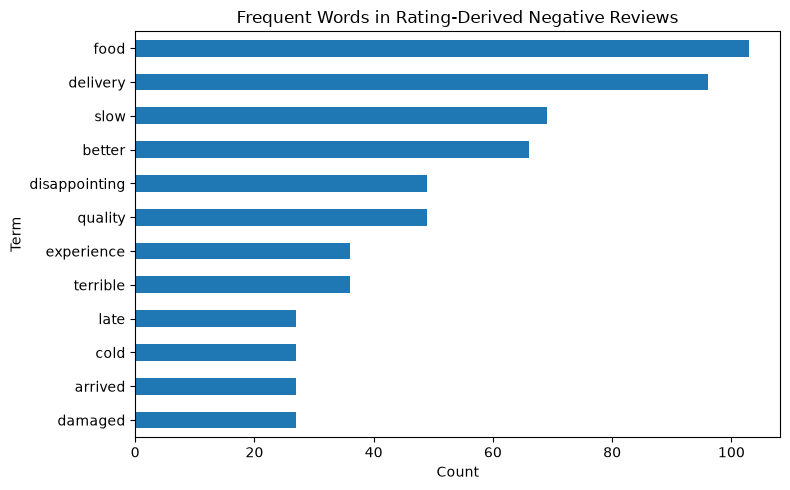

In [13]:
negative_reviews = reviews[
    reviews["sentiment"] == "negative"
].copy()

print("Negative review rows:", len(negative_reviews))

display(
    negative_reviews[
        [TEXT_COL, RATING_COL, "cleaned_text"]
    ].head(20)
)

tokens = []

for text in negative_reviews["cleaned_text"]:
    tokens.extend(text.split())

complaint_terms = pd.DataFrame(
    Counter(tokens).most_common(20),
    columns=["term", "count"]
)

display(complaint_terms)

complaint_terms.to_csv(
    PROCESSED_DIR / "complaint_themes.csv",
    index=False
)

if not complaint_terms.empty:

    ax = complaint_terms.sort_values(
        "count"
    ).plot(
        x="term",
        y="count",
        kind="barh",
        legend=False,
        figsize=(8, 5)
    )

    ax.set_title(
        "Frequent Words in Rating-Derived Negative Reviews"
    )
    ax.set_xlabel("Count")
    ax.set_ylabel("Term")

    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / "complaint_terms.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()

,vader_sentiment,rating
0,negative,2.133663
1,neutral,3.194737
2,positive,4.434379


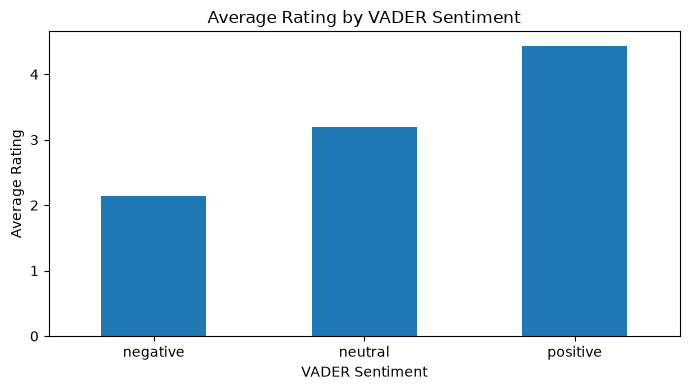

In [14]:
avg_rating_vader = (
    reviews.groupby("vader_sentiment")[RATING_COL]
    .mean()
    .reset_index()
)

display(avg_rating_vader)

ax = avg_rating_vader.plot(
    x="vader_sentiment",
    y=RATING_COL,
    kind="bar",
    legend=False,
    figsize=(7, 4)
)

ax.set_title("Average Rating by VADER Sentiment")
ax.set_xlabel("VADER Sentiment")
ax.set_ylabel("Average Rating")

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "average_rating_by_vader_sentiment.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()